# How lsdb builds dask task graphs

A ground-up walkthrough of what `operation.build()` actually does, why it exists, and why
building one partition at a time costs what it does.

Written to be read start to finish with no prior dask internals. It uses a **12-partition
toy catalog** throughout -- small enough to draw every node -- and returns to the real
33,055-partition Hugging Face catalog only at the end, to connect back to the streaming
profile in `stream-hf-profile.ipynb`.

**Roadmap**

| part | question |
|---|---|
| 1 | What *is* a task graph? |
| 2 | What does `Delayed` add? |
| 3 | How does modern dask represent a task? |
| 4 | Why does lsdb need its own layer on top? |
| 5 | The simplest operation: `FromHealpixMap` |
| 6 | What one-pixel builds actually cost |
| 7 | Composed chains: `build()` recurses |
| 8 | Why the cost compounds per layer |
| 9 | Back to streaming |

In [1]:
from operator import add, mul
from time import perf_counter

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

import dask
from dask._task_spec import Task, TaskRef
from dask.delayed import Delayed
from dask.threaded import get as threaded_get

import lsdb

plt.rcParams.update({
    "axes.titlesize": 16, "axes.labelsize": 15,
    "xtick.labelsize": 13, "ytick.labelsize": 13,
    "legend.fontsize": 13, "figure.titlesize": 18,
})

# Reference palette slots, used consistently for node roles throughout.
BLUE, ORANGE, AQUA, YELLOW, PINK = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
GRAY, INK, MUTED = "#c9c9c4", "#0b0b0b", "#8a8a85"

print("dask", dask.__version__, "| lsdb", lsdb.__version__, "| networkx", nx.__version__)

dask 2026.3.0 | lsdb 0.10.5.dev1+g36a32399e | networkx 3.6


## 1. What is a task graph?

Dask's central idea is small enough to state in one sentence:

> **A task graph is a dictionary mapping a *key* to a *task*, where a task is a function
> plus its arguments, and an argument may be the key of another task.**

That last clause is what makes it a *graph*: when task `b`'s arguments mention key `a`,
`b` depends on `a`, and that is an edge.

Nothing is computed while you build this dictionary. You are writing down a **plan**. A
scheduler executes it later, and because it can see the whole plan at once it can decide
what to run in parallel, what order to run it in, and what to throw away.

Here is a complete dask graph, written by hand in the classic tuple form -- a task is a
tuple `(function, *arguments)`, and a bare string is a reference to another key:

In [2]:
dsk = {
    "x": 10,                 # a plain value, no computation
    "y": 20,
    "a": (add, "x", "y"),    # add(x, y)  -> depends on x and y
    "b": (mul, "a", 2),      # mul(a, 2)  -> depends on a
}

# Nothing has run yet. dsk is just a dict.
print(type(dsk), len(dsk), "entries")

# Ask a scheduler for one key. It runs only what that key needs.
print("b =", threaded_get(dsk, "b"))
print("a =", threaded_get(dsk, "a"))

<class 'dict'> 4 entries
b = 60
a = 30


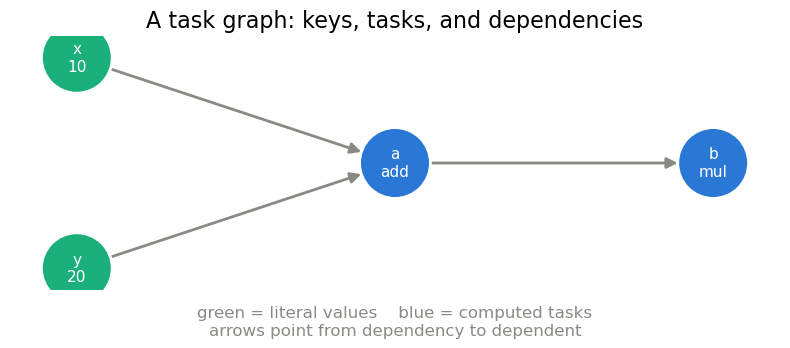

In [3]:
def draw_nodes(ax, g, pos, labels, node_colors, title, node_size=2600, font_size=11,
               edge_color=MUTED):
    """Draw a directed graph with our node-role colors. Shared by every figure below."""
    nx.draw_networkx_edges(ax=ax, G=g, pos=pos, edge_color=edge_color, width=2,
                           arrowsize=16, node_size=node_size)
    nx.draw_networkx_nodes(ax=ax, G=g, pos=pos, node_color=node_colors,
                           node_size=node_size, edgecolors="white", linewidths=2)
    nx.draw_networkx_labels(ax=ax, G=g, pos=pos, labels=labels,
                            font_size=font_size, font_color="white")
    ax.set_title(title)
    ax.set_axis_off()


def legacy_to_nx(dsk):
    """Build a DiGraph from a classic tuple-form dask graph."""
    g = nx.DiGraph()
    g.add_nodes_from(dsk)
    for key, task in dsk.items():
        if isinstance(task, tuple) and callable(task[0]):
            for arg in task[1:]:
                if isinstance(arg, str) and arg in dsk:
                    g.add_edge(arg, key)
    return g


g = legacy_to_nx(dsk)
pos = {"x": (0, 1), "y": (0, -1), "a": (1, 0), "b": (2, 0)}
# Data nodes vs computed nodes -- the distinction the tuple form encodes by type.
colors = [AQUA if k in ("x", "y") else BLUE for k in g.nodes]
labels = {"x": "x\n10", "y": "y\n20", "a": "a\nadd", "b": "b\nmul"}

fig, ax = plt.subplots(figsize=(8, 3.6))
draw_nodes(ax, g, pos, labels, colors, "A task graph: keys, tasks, and dependencies")
ax.text(0.5, -0.06, "green = literal values    blue = computed tasks\narrows point from dependency to dependent",
        transform=ax.transAxes, ha="center", va="top", fontsize=12, color=MUTED)
fig.tight_layout()
plt.show()

## 2. `Delayed`: the same dictionary, written for you

Writing graph dicts by hand gets old fast. `dask.delayed` wraps a function so that calling
it *records* the call instead of running it, returning a `Delayed` object that carries the
graph built so far.

The important thing for this notebook: **a `Delayed` is just a (key, graph) pair.** Its
`.key` says which node you want, and `.dask` is the dictionary. That is exactly the shape
lsdb's streaming code constructs by hand -- we will see it in part 9.

In [4]:
@dask.delayed
def load(n):
    return n

@dask.delayed
def combine(a, b):
    return a + b

result = combine(load(10), load(20))

print("type       :", type(result))
print("result.key :", result.key)
print("graph size :", len(dict(result.dask)), "nodes")
print("keys       :")
for k in dict(result.dask):
    print("   ", k)
print("values     :")
for k, v in dict(result.dask).items():
    print("   ", k[:10], "... :", v)
print()
print("computed   :", result.compute())

type       : <class 'dask.delayed.Delayed'>
result.key : combine-f7f2a927-2bf8-4cb8-9a94-2182894b8d5e
graph size : 3 nodes
keys       :
    combine-f7f2a927-2bf8-4cb8-9a94-2182894b8d5e
    load-0cfb2264-e6ae-49b1-9920-4d641dca7457
    load-a1635650-5615-41a2-b320-d08d3cf448a4
values     :
    combine-f7 ... : <Task 'combine-f7f2a927-2bf8-4cb8-9a94-2182894b8d5e' combine(...)>
    load-0cfb2 ... : <Task 'load-0cfb2264-e6ae-49b1-9920-4d641dca7457' load(...)>
    load-a1635 ... : <Task 'load-a1635650-5615-41a2-b320-d08d3cf448a4' load(...)>

computed   : 30


In [5]:
result.dask

HighLevelGraph with 3 layers.
<dask.highlevelgraph.HighLevelGraph object at 0x7fe855c41a90>
 0. load-a1635650-5615-41a2-b320-d08d3cf448a4
 1. load-0cfb2264-e6ae-49b1-9920-4d641dca7457
 2. combine-f7f2a927-2bf8-4cb8-9a94-2182894b8d5e

In [7]:
task = [v for k, v in dict(result.dask).items() if "combine" in k][0]
print("task:", task)
print("args:", task.args)
print("deps:", task.dependencies)
print("func:", task.func)
print("kwargs:", task.kwargs)
print()
task = [v for k, v in dict(result.dask).items() if "load" in k][0]
print("task:", task)
print("args:", task.args)
print("deps:", task.dependencies)
print("func:", task.func)
print("kwargs:", task.kwargs)

task: <Task 'combine-f7f2a927-2bf8-4cb8-9a94-2182894b8d5e' combine(...)>
args: (TaskRef('load-0cfb2264-e6ae-49b1-9920-4d641dca7457'), TaskRef('load-a1635650-5615-41a2-b320-d08d3cf448a4'))
deps: frozenset({'load-a1635650-5615-41a2-b320-d08d3cf448a4', 'load-0cfb2264-e6ae-49b1-9920-4d641dca7457'})
func: <function combine at 0x7fe855c700e0>
kwargs: {}

task: <Task 'load-0cfb2264-e6ae-49b1-9920-4d641dca7457' load(...)>
args: (10,)
deps: frozenset()
func: <function load at 0x7fe855c70180>
kwargs: {}


## 3. How modern dask represents a task

The `Task` objects in the cells just above are not a `delayed` detail -- they are how current
dask stores *every* graph. `dask._task_spec.Task` is the node type, and even the hand-written
tuple dict from part 1 is converted into one before a scheduler ever sees it:

```python
>>> from dask._task_spec import convert_legacy_graph
>>> convert_legacy_graph(dsk)
{'x': DataNode(10), 'y': DataNode(20),
 'a': <Task 'a' add(Alias('x'), Alias('y'))>,
 'b': <Task 'b' mul(Alias('a'), 2)>}
```

So the tuple form is a front end you may write in; `Task` is what dask actually holds. Three
pieces:

- `Task(key, func, *args, **kwargs)` -- the node
- `TaskRef(other_key)` -- an argument meaning *"the result of that other task"*
- `.dependencies` -- the keys this task needs, derived for you from the `TaskRef`s

The distinction worth pausing on is `TaskRef` versus the bare string of part 1. In
`(add, "x", "y")`, dask has to *guess* whether `"x"` names a key or is a literal string
argument, and it guesses by testing membership in the graph dict. `TaskRef("x")` states it
outright, so `.dependencies` is exact rather than inferred.

That exactness is what the rest of the notebook leans on. lsdb constructs these objects by
hand rather than going through `delayed`, and part 7 stitches layers together by reading
`.dependencies` back off them -- edges you can trust because they were declared, not sniffed.

The cell below builds a two-node graph from `Task` objects directly. It is the only place we
construct one by hand; from part 5 on, lsdb does it for us.

In [5]:
leaf = Task("leaf", lambda: 10)
stem = Task("stem", lambda v, k: v * k, TaskRef("leaf"), 3)

print("leaf.key          :", leaf.key)
print("leaf.args         :", leaf.args)
print("leaf.dependencies :", set(leaf.dependencies), "  <- nothing to wait for")
print()
print("stem.args         :", stem.args)
print("stem.dependencies :", set(stem.dependencies), "  <- the edge, stated explicitly")
print()
# A graph is still just a dict of these.
spec_graph = {t.key: t for t in (leaf, stem)}
print("graph:", spec_graph)

leaf.key          : leaf
leaf.args         : ()
leaf.dependencies : set()   <- nothing to wait for

stem.args         : (TaskRef('leaf'), 3)
stem.dependencies : {'leaf'}   <- the edge, stated explicitly

graph: {'leaf': <Task 'leaf' lambda()>, 'stem': <Task 'stem' lambda(TaskRef('leaf'), 3)>}


## 4. Why lsdb adds its own layer

A HATS catalog is sharded on the sky: each partition is one **HEALPix pixel**, identified by
an `(order, pixel)` pair rather than by an integer position. Two things follow.

**First, lsdb needs to address partitions by pixel.** A crossmatch has to line up *this*
catalog's pixel 42 against *that* catalog's pixel 42, which a bare dask graph -- a flat dict
of opaque keys -- gives you no way to express. So lsdb wraps every graph it produces in a
`HealpixGraph`, which is nothing more than:

```python
class HealpixGraph:
    def __init__(self, graph, pixel_to_key_map):
        self.graph = graph                      # the dask graph dict
        self.pixel_to_key_map = pixel_to_key_map  # HealpixPixel -> key
```

The second field is the whole point: it says *which key holds the answer for which pixel*.

**Second, lsdb keeps its own plan.** Rather than build dask tasks as you chain operations,
each step appends an `Operation` -- `FromHealpixMap`, `SelectColumns`, `MapPartitions` --
to a small linked structure reachable via `.dependencies`. Calling `.build()` walks that
plan and *materializes* a dask graph from it.

So there are **two graphs**, at different scales, and keeping them apart is the key idea:

| | lsdb `Operation` plan | dask task graph |
|---|---|---|
| one node per | *step* | *step x pixel* |
| toy catalog, 3 steps | 3 nodes | 36 nodes |
| gaia, 3 steps | 3 nodes | 99,165 nodes |
| built when | you chain calls | you call `.build()` |

Let's look at the plan first.

In [6]:
cat = lsdb.generate_catalog(500, 10, seed=1)
print("toy catalog npartitions:", cat.npartitions)
print("healpix pixels:", cat._operation.healpix_pixels[:4], "...")
print()

def walk_plan(op, indent=0):
    '''Print the Operation plan by following .dependencies.'''
    print("  " * indent + f"- {type(op).__name__}")
    for dep in op.dependencies:
        walk_plan(dep, indent + 1)

print("plan for a plain read:")
walk_plan(cat._operation)

chained = cat[["ra", "dec"]].map_partitions(lambda df: df.assign(x=1))
print("\nplan after  cat[['ra','dec']].map_partitions(...):")
walk_plan(chained._operation)

toy catalog npartitions: 12
healpix pixels: [Order: 0, Pixel: 0, Order: 0, Pixel: 1, Order: 0, Pixel: 2, Order: 0, Pixel: 3] ...

plan for a plain read:
- FromHealpixMap

plan after  cat[['ra','dec']].map_partitions(...):
- MapPartitions
  - SelectColumns
    - FromHealpixMap


## 5. The simplest operation: `FromHealpixMap`

A plain catalog read is a single `Operation` whose job is: *for each pixel, call
`read_pixel` on it*. Its `build()` produces one dask task per pixel, and those tasks are
**completely independent** -- no task reads another's output, so the graph has 12 nodes and
zero edges.

That shape is worth internalizing, because it is why streaming works at all: any single
partition can be computed without touching the other eleven.

In [7]:
op = cat._operation
built = op.build()          # no pixels= argument: build everything

print("returned          :", type(built).__name__)
print("built.graph       :", type(built.graph).__name__, "with", len(built.graph), "nodes")
print("edges             :", sum(len(t.dependencies) for t in built.graph.values()))
print()
key = built.pixel_to_key_map[op.healpix_pixels[3]]
print("pixel 3 maps to key:", key)
task = built.graph[key]
print("  task.func       :", task.func)
print("  task.args       :", task.args)

returned          : HealpixGraph
built.graph       : dict with 12 nodes
edges             : 0

pixel 3 maps to key: ('_pixel_df-4a5bc17f92db8a4cf82b97ebf4d50035', 3)
  task.func       : <function _pixel_df at 0x7f5f88696520>
  task.args       : (Order: 0, Pixel: 3,)


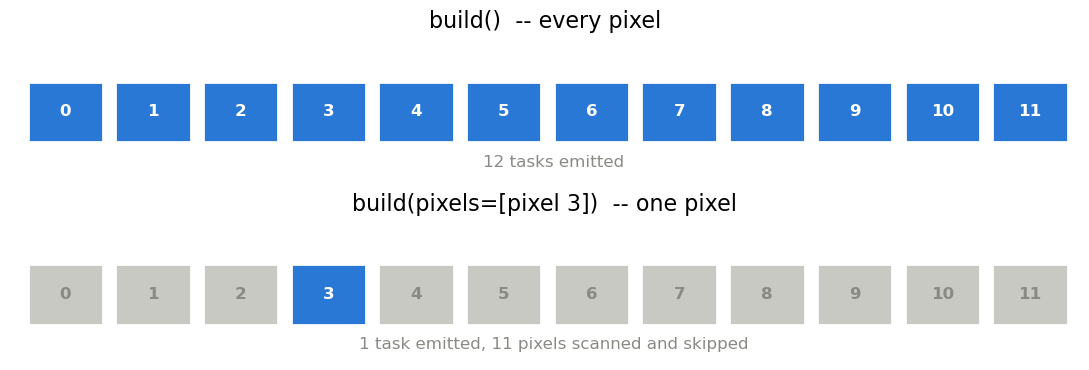

In [8]:
def draw_pixel_row(ax, pixels, emitted_idx, title, subtitle=None):
    """Draw one box per pixel; highlight those a build() actually emitted."""
    n = len(pixels)
    for i in range(n):
        on = i in emitted_idx
        ax.add_patch(plt.Rectangle((i, 0), 0.86, 0.86,
                                   facecolor=BLUE if on else GRAY,
                                   edgecolor="white", linewidth=2))
        ax.text(i + 0.43, 0.43, str(i), ha="center", va="center",
                color="white" if on else MUTED, fontsize=12, fontweight="bold")
    ax.set_xlim(-0.2, n); ax.set_ylim(-0.5, 1.5)
    ax.set_title(title); ax.set_axis_off()
    if subtitle:
        ax.text(n / 2, -0.35, subtitle, ha="center", fontsize=12, color=MUTED)


pixels = op.healpix_pixels
one = op.build(pixels=[pixels[3]])

fig, axes = plt.subplots(2, 1, figsize=(11, 3.8))
draw_pixel_row(axes[0], pixels, set(range(len(pixels))),
               "build()  -- every pixel", f"{len(built.graph)} tasks emitted")
draw_pixel_row(axes[1], pixels, {3},
               "build(pixels=[pixel 3])  -- one pixel",
               f"{len(one.graph)} task emitted, {len(pixels) - 1} pixels scanned and skipped")
fig.tight_layout()
plt.show()

## 6. What a one-pixel build costs

The bottom row above hides the thing this whole notebook is about. Here is
`FromHealpixMap.build`, trimmed to its loop:

```python
def build(self, pixels=None):
    target = set(pixels) if pixels is not None else None
    graph, pixel_keys = {}, {}
    for i, pixel in enumerate(self.pixels):        # EVERY pixel in the catalog
        if target is not None and pixel not in target:
            continue                               # ...just to skip most of them
        key = (self.key_name, i)
        graph[key] = Task(key, func, pixel, *self.args, **self.kwargs)
        pixel_keys[pixel] = key
    return HealpixGraph(graph, pixel_keys)
```

The `pixels=` filter does not make the loop shorter. It makes the loop *skip*. To emit one
task, the function walks the entire pixel list and hash-tests each one against a set.

With 12 pixels that is free. The gaia catalog has **33,055**, and the cost is linear in
that number -- so let's measure it on the real thing.

In [9]:
GAIA = "hf://datasets/UniverseTBD/mmu_gaia_gaia@main/mmu_gaia_gaia"
gaia = lsdb.open_catalog(GAIA)
print("gaia npartitions:", gaia.npartitions)

gaia npartitions: 33055


In [10]:
import cProfile, io, pstats

gop = gaia._operation
gpx = gop.healpix_pixels
gop.key_name, gop.meta          # warm cached properties so we time the loop only

N = 20
pr = cProfile.Profile(); pr.enable()
for k in range(N):
    gop.build(pixels=[gpx[k]])
pr.disable()

s = io.StringIO(); pstats.Stats(pr, stream=s).sort_stats("tottime").print_stats(3)
print(s.getvalue())
print(f"{N} builds x {gaia.npartitions:,} pixels = {N * gaia.npartitions:,} expected hash tests")
print(f"each build emitted {len(gop.build(pixels=[gpx[0]]).graph)} task")

         1323605 function calls (1323600 primitive calls) in 0.350 seconds

   Ordered by: internal time
   List reduced from 120 to 3 due to restriction <3>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
       20    0.137    0.007    0.331    0.017 /sdf/home/o/olynn/.local/lib/python3.13/site-packages/lsdb/operations/lsdb_ops.py:104(build)
   661140    0.133    0.000    0.207    0.000 <string>:39(__hash__)
   661142    0.074    0.000    0.074    0.000 {built-in method builtins.hash}



20 builds x 33,055 pixels = 661,100 expected hash tests
each build emitted 1 task


## 7. Composed chains: `build()` recurses

Chaining operations gives the plan more steps. Every `MapPartitions`-style operation builds
by **first asking its base to build**, then adding one task per pixel that consumes the
base's task:

```python
def build(self, pixels=None):
    previous = self.base.build(pixels=pixels)          # recurse into the layer below
    graph = previous.graph                             # keep its nodes
    for pixel, prev_key in previous.pixel_to_key_map.items():
        key = (self.key_name, i)
        graph[key] = Task(key, task_func, TaskRef(prev_key), ...)   # <- the edge
    return HealpixGraph(graph, pixel_keys)
```

So a 3-step plan over 12 pixels produces 36 tasks in 12 independent chains of 3. And a
one-pixel build of that same plan produces exactly one chain of 3.

In [11]:
cop = chained._operation
cfull = cop.build()
cone = cop.build(pixels=[cop.healpix_pixels[3]])

from collections import Counter
print("full build   :", len(cfull.graph), "nodes ->", dict(Counter(k[0].split("-")[0] for k in cfull.graph)))
print("one-pixel    :", len(cone.graph), "nodes")
print()
for k, t in cone.graph.items():
    deps = {d[0].split("-")[0] for d in t.dependencies}
    print(f"  {k[0].split('-')[0]:14s} idx={k[1]}  depends on {deps or '{}'}")
print()
print("terminal key for that pixel:", cone.pixel_to_key_map[cop.healpix_pixels[3]][0].split("-")[0])

full build   : 36 nodes -> {'_pixel_df': 12, 'SelectColumns': 12, 'lambda': 12}
one-pixel    : 3 nodes

  _pixel_df      idx=3  depends on {}
  SelectColumns  idx=3  depends on {'_pixel_df'}
  lambda         idx=3  depends on {'SelectColumns'}

terminal key for that pixel: lambda


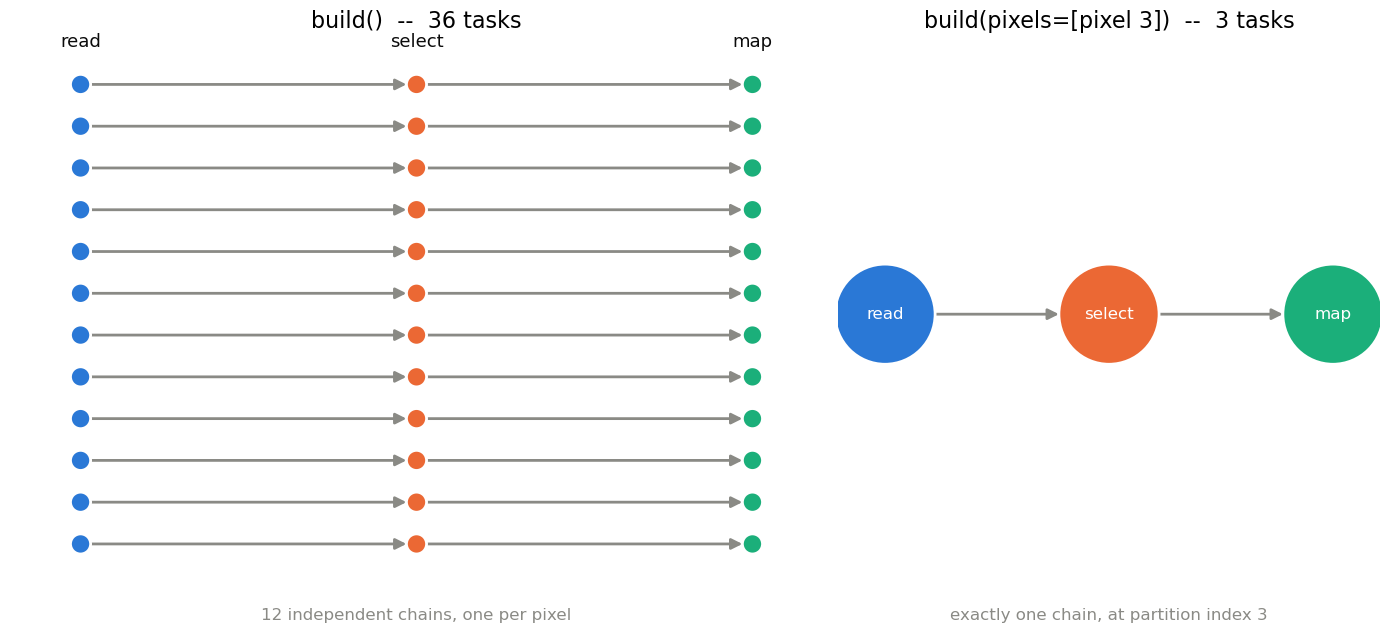

In [12]:
def graph_to_nx(graph):
    """dask graph dict -> DiGraph, using Task.dependencies for edges."""
    g = nx.DiGraph()
    g.add_nodes_from(graph)
    for key, task in graph.items():
        for dep in task.dependencies:
            if dep in graph:
                g.add_edge(dep, key)
    return g


def layered_pos(g):
    """x = topological depth, y = partition index (key[1])."""
    pos = {}
    for depth, generation in enumerate(nx.topological_generations(g)):
        for node in generation:
            pos[node] = (depth, -node[1])
    return pos


# Short display names: the full key prefixes ("SelectColumns") overflow a node marker.
SHORT = {"_pixel_df": "read", "SelectColumns": "select", "lambda": "map"}
LAYER = {"_pixel_df": BLUE, "SelectColumns": ORANGE, "lambda": AQUA}
step = lambda n: n[0].split("-")[0]

gf, go = graph_to_nx(cfull.graph), graph_to_nx(cone.graph)
pf, po = layered_pos(gf), layered_pos(go)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6.4), width_ratios=[1.5, 1])

draw_nodes(a1, gf, pf, {n: "" for n in gf.nodes}, [LAYER[step(n)] for n in gf.nodes],
           f"build()  --  {len(cfull.graph)} tasks", node_size=210)
for d, name in enumerate(["read", "select", "map"]):
    a1.text(d, 0.9, name, ha="center", fontsize=13, color=INK)
a1.text(0.5, -0.05, "12 independent chains, one per pixel", transform=a1.transAxes,
        ha="center", fontsize=12, color=MUTED)

draw_nodes(a2, go, po, {n: SHORT[step(n)] for n in go.nodes},
           [LAYER[step(n)] for n in go.nodes],
           f"build(pixels=[pixel 3])  --  {len(cone.graph)} tasks",
           node_size=5200, font_size=12)
a2.text(0.5, -0.05, "exactly one chain, at partition index 3", transform=a2.transAxes,
        ha="center", fontsize=12, color=MUTED)

fig.tight_layout()
plt.show()

## 8. The cost compounds with every layer

Here is the consequence that is easy to miss. Each layer's `build()` runs its *own* full
pass over the pixel list -- `FromHealpixMap` scans to filter, and `MapPartitions` builds a
`{pixel: index}` map over `self.healpix_pixels` -- so a one-pixel build of an *n*-layer plan
walks the catalog *n* times.

The work is **O(layers x npartitions)** to emit **O(layers)** tasks. Measured on gaia:

In [13]:
chains = {
    "1  read": gaia,
    "2  + select_columns": gaia[["ra", "dec"]],
    "3  + map_partitions": gaia[["ra", "dec"]].map_partitions(lambda df: df.assign(x=1)),
}

rows = []
for name, c in chains.items():
    o = c._operation
    o.key_name, o.meta
    N = 15
    t0 = perf_counter()
    for k in range(N):
        o.build(pixels=[gpx[k]])
    ms = 1e3 * (perf_counter() - t0) / N
    rows.append({"chain": name, "build_1px_ms": ms,
                 "tasks_emitted": len(o.build(pixels=[gpx[0]]).graph),
                 "pixels_walked": int(name.split()[0]) * gaia.npartitions})

depth = pd.DataFrame(rows).set_index("chain")
depth.round(2)

,build_1px_ms,tasks_emitted,pixels_walked
chain,,,
1 read,6.53,1,33055
2 + select_columns,13.59,2,66110
3 + map_partitions,20.99,3,99165


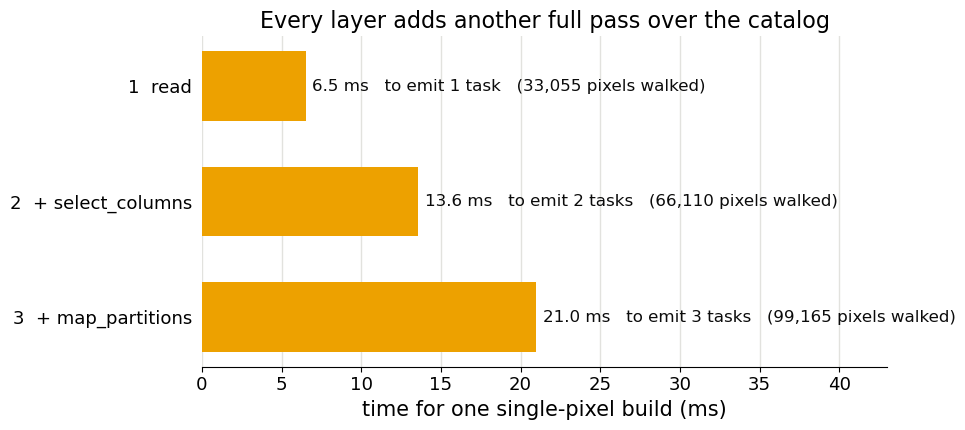

In [14]:
fig, ax = plt.subplots(figsize=(9.5, 4.4))
y = np.arange(len(depth))[::-1]
ax.barh(y, depth["build_1px_ms"], height=0.6, color=YELLOW)
for yi, (ms, n, walked) in zip(y, depth[["build_1px_ms", "tasks_emitted", "pixels_walked"]].values):
    ax.text(ms + 0.4, yi, f"{ms:.1f} ms   to emit {int(n)} task{'s' if n > 1 else ''}"
                          f"   ({int(walked):,} pixels walked)",
            va="center", fontsize=12, color=INK)
ax.set_yticks(y, depth.index)
ax.set_xlim(0, depth["build_1px_ms"].max() * 2.05)
ax.set_xlabel("time for one single-pixel build (ms)")
ax.set_title("Every layer adds another full pass over the catalog")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", color="#e2e2de", linewidth=1); ax.set_axisbelow(True)
ax.tick_params(left=False)
fig.tight_layout()
plt.show()

## 9. Back to streaming

Now the streaming code reads plainly. From `CatalogStream.submit_next_partitions`:

```python
def _to_delayed(operation, pixel):
    build = operation.build(pixels=[pixel])      # scan the catalog, emit one chain
    graph = build.graph                          # the dict
    key = build.pixel_to_key_map[pixel]          # which node holds this pixel's answer
    return Delayed(key, graph)                   # the (key, graph) pair from part 2
```

That is the entire connection: `HealpixGraph` carries a graph plus a pixel-to-key map,
`Delayed` wants a key plus a graph, and `pixel_to_key_map[pixel]` is the adapter between
them.

And the cost model follows directly. Per chunk the stream calls `_to_delayed` once **per
partition**, so it walks the full pixel list `partitions_per_chunk x layers` times, to emit
`partitions_per_chunk x layers` tasks.

In [15]:
pixel = gpx[7]
b = gop.build(pixels=[pixel])
d = Delayed(b.pixel_to_key_map[pixel], b.graph)

print("Delayed key :", d.key)
print("graph size  :", len(dict(d.dask)), "node")
print()
t0 = perf_counter(); df = d.compute(); t1 = perf_counter()
print(f"compute()   : {t1 - t0:.2f}s  ->  {len(df):,} rows")
print()
ppc, layers = 2, 1
print(f"per chunk at partitions_per_chunk={ppc}, {layers} layer:")
print(f"  pixels walked : {ppc * layers * gaia.npartitions:,}")
print(f"  tasks emitted : {ppc * layers}")

Delayed key : ('read_pixel-c53ec49d82b51c2bc176c3fb46ecd6ad', 7)
graph size  : 1 node



compute()   : 1.08s  ->  6,001 rows

per chunk at partitions_per_chunk=2, 1 layer:
  pixels walked : 66,110
  tasks emitted : 2


## Recap: the mental model

1. **A dask task graph is a dict**: key -> `Task(func, *args)`, where a `TaskRef` argument is
   an edge. Building it computes nothing; a scheduler runs it later.
2. **A `Delayed` is a (key, graph) pair** -- one node you want, plus the dict needed to get it.
3. **lsdb keeps a second, much smaller graph**: the `Operation` plan, one node per *step*.
   `build()` turns *steps* into *steps x pixels*.
4. **`HealpixGraph` is the bridge**: the dask graph, plus `pixel_to_key_map` saying which key
   answers which pixel. That map is what lets lsdb align catalogs by sky position, and what
   lets the streamer pull a single partition.
5. **`build(pixels=[p])` filters by skipping, not by indexing.** It walks every pixel in the
   catalog to emit one task, once per layer -- O(layers x npartitions) work for O(layers)
   output.

Point 5 is a *latency* cost, not a throughput one. `stream-hf-profile.ipynb` measures where
it actually lands: about **0.8%** of wall time when streaming gaia, because the network
dominates -- but **209 s** across a full 33,055-partition pass, against **0.35 s** to build
the entire graph in one call.